# Mars Landform Classification using MobileNetV2

Transfer learning approach using pretrained MobileNetV2 for multi-class classification of Mars surface images.

## 1. Import Libraries

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
import time

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import torchvision
from torchvision import transforms, models

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, classification_report

print(f'PyTorch version: {torch.__version__}')
print(f'Torchvision version: {torchvision.__version__}')
print(f'CUDA available: {torch.cuda.is_available()}')

PyTorch version: 2.10.0+cu128
Torchvision version: 0.25.0+cu128
CUDA available: True


## 2. Configuration

In [2]:
BASE = '/kaggle/input/datasets/qasimchaudry/hirise-mars-surface-image-datasets'

dataset_dirs = [
    f'{BASE}/hirise-map-proj-v3_2/hirise-map-proj-v3_2/map-proj-v3_2',
    f'{BASE}/hirise-map-proj-v3/hirise-map-proj-v3/map-proj-v3',
]
labels_file = f'{BASE}/hirise-map-proj-v3_2/hirise-map-proj-v3_2/labels-map-proj_v3_2_train_val_test.txt'

class_names = [
    'other',
    'crater',
    'dark dune',
    'slope streak',
    'bright dune',
    'impact ejecta',
    'swiss cheese',
    'spider'
]
num_classes = len(class_names)

image_size              = 224
batch_size              = 32
num_epochs              = 50
learning_rate           = 0.001
weight_decay            = 1e-4
early_stopping_patience = 15

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'using device: {device}')
if torch.cuda.is_available():
    print(f'gpu: {torch.cuda.get_device_name(0)}')
    print(f'vram: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB')

model_save_path       = 'best_mars_mobilenet_model.pth'
inference_config_path = 'mobilenet_inference_config.json'


using device: cuda
gpu: Tesla T4
vram: 15.6 GB


## 3. Load Dataset

In [3]:
# Load labels file
df = pd.read_csv(labels_file, sep=' ', header=None, names=['filename', 'label', 'split'])
print(f'Total samples: {len(df)}')
print(f'\nSplit distribution:')
print(df['split'].value_counts())
print(f'\nClass distribution:')
print(df['label'].value_counts().sort_index())

Total samples: 67810

Split distribution:
split
train    51058
val      14959
test      1793
Name: count, dtype: int64

Class distribution:
label
0    52722
1     5857
2      857
3     1603
4     1654
5      777
6     2772
7     1568
Name: count, dtype: int64


In [4]:
# Function to find image path across multiple directories
def find_image_path(filename, dataset_dirs):
    for base_dir in dataset_dirs:
        full_path = os.path.join(base_dir, filename)
        if os.path.exists(full_path):
            return full_path
    return None

# Verify images exist and filter dataset
valid_indices = []
for idx, row in df.iterrows():
    if find_image_path(row['filename'], dataset_dirs) is not None:
        valid_indices.append(idx)

df = df.loc[valid_indices].reset_index(drop=True)
print(f'Valid samples: {len(df)}')

# Split data
train_df = df[df['split'] == 'train'].reset_index(drop=True)
val_df = df[df['split'] == 'val'].reset_index(drop=True)
test_df = df[df['split'] == 'test'].reset_index(drop=True)

print(f'\nTrain samples: {len(train_df)}')
print(f'Validation samples: {len(val_df)}')
print(f'Test samples: {len(test_df)}')

Valid samples: 67810

Train samples: 51058
Validation samples: 14959
Test samples: 1793


## 4. Calculate Class Weights

In [5]:
# Calculate class weights for balanced training
train_class_counts = np.bincount(train_df['label'].values, minlength=num_classes)
total_samples = len(train_df)
class_weights = total_samples / (num_classes * (train_class_counts + 1e-6))
class_weights = torch.FloatTensor(class_weights).to(device)

print('Class weights:')
for i, (name, weight) in enumerate(zip(class_names, class_weights.cpu().numpy())):
    print(f'{name}: {weight:.4f}')

Class weights:
other: 0.1595
crater: 1.4729
dark dune: 9.9103
slope streak: 6.8041
bright dune: 4.0886
impact ejecta: 11.8409
swiss cheese: 3.3276
spider: 5.7706


## 5. Define Dataset Class

In [6]:
class MarsDataset(Dataset):
    def __init__(self, dataframe, dataset_dirs, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.dataset_dirs = dataset_dirs
        self.transform = transform
    
    def __len__(self):
        return len(self.dataframe)
    
    def __getitem__(self, idx):
        row = self.dataframe.iloc[idx]
        filename = row['filename']
        label = row['label']
        
        img_path = find_image_path(filename, self.dataset_dirs)
        image = Image.open(img_path).convert('RGB')
        
        if self.transform:
            image = self.transform(image)
        
        return image, label

print('Dataset class defined')

Dataset class defined


## 6. Define Data Transforms

In [7]:
# ImageNet normalization
mean = [0.485, 0.456, 0.406]
std = [0.229, 0.224, 0.225]

# Training transforms with augmentation
train_transform = transforms.Compose([
    transforms.Resize((image_size, image_size)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std)
])

# Validation/test transforms without augmentation
val_transform = transforms.Compose([
    transforms.Resize((image_size, image_size)),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std)
])

print('Transforms defined')

Transforms defined


## 7. Create DataLoaders

In [8]:
train_dataset = MarsDataset(train_df, dataset_dirs, transform=train_transform)
val_dataset   = MarsDataset(val_df,   dataset_dirs, transform=val_transform)
test_dataset  = MarsDataset(test_df,  dataset_dirs, transform=val_transform)

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True,
                          num_workers=2, pin_memory=True, persistent_workers=False)
val_loader   = DataLoader(val_dataset,   batch_size=batch_size, shuffle=False,
                          num_workers=2, pin_memory=True, persistent_workers=False)
test_loader  = DataLoader(test_dataset,  batch_size=batch_size, shuffle=False,
                          num_workers=2, pin_memory=True, persistent_workers=False)

print(f'train batches:      {len(train_loader)}')
print(f'validation batches: {len(val_loader)}')
print(f'test batches:       {len(test_loader)}')


train batches:      1596
validation batches: 468
test batches:       57


## 8. Load MobileNetV2 Model

In [9]:
model = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.IMAGENET1K_V1)
print('loaded pretrained mobilenetv2')

for param in model.features.parameters():
    param.requires_grad = False

num_features = model.classifier[1].in_features
model.classifier[1] = nn.Linear(num_features, num_classes)

model = model.to(device)

total_params     = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f'total parameters:     {total_params:,}')
print(f'trainable parameters: {trainable_params:,}')
print(f'frozen parameters:    {total_params - trainable_params:,}')


Downloading: "https://download.pytorch.org/models/mobilenet_v2-b0353104.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-b0353104.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 202MB/s]

loaded pretrained mobilenetv2
total parameters:     2,234,120
trainable parameters: 10,248
frozen parameters:    2,223,872


## 9. Define Loss and Optimizer

In [10]:
# Loss function with class weights
criterion = nn.CrossEntropyLoss(weight=class_weights)

# Optimizer for trainable parameters only
optimizer = optim.Adam(filter(lambda p: p.requires_grad, model.parameters()),
                      lr=learning_rate, weight_decay=weight_decay)

print('Loss function: CrossEntropyLoss with class weights')
print(f'Optimizer: Adam with lr={learning_rate}')

Loss function: CrossEntropyLoss with class weights
Optimizer: Adam with lr=0.001


## 10. Training and Validation Functions

In [11]:
from torch.cuda.amp import autocast, GradScaler

scaler = GradScaler()


def train_epoch(model, loader, criterion, optimizer, device):
    model.train()
    running_loss = 0.0
    correct = 0
    total   = 0

    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad()

        with autocast():
            outputs = model(images)
            loss    = criterion(outputs, labels)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item() * images.size(0)
        _, predicted  = outputs.max(1)
        total   += labels.size(0)
        correct += predicted.eq(labels).sum().item()

        del images, labels, outputs, loss

    return running_loss / total, correct / total


def validate_epoch(model, loader, criterion, device):
    model.eval()
    running_loss = 0.0
    correct = 0
    total   = 0

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            with autocast():
                outputs = model(images)
                loss    = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)
            _, predicted  = outputs.max(1)
            total   += labels.size(0)
            correct += predicted.eq(labels).sum().item()

            del images, labels, outputs, loss

    return running_loss / total, correct / total


print('training functions defined (mixed precision)')


training functions defined (mixed precision)


/tmp/ipykernel_23/3416911140.py:3: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler()


## 11. Train Model

In [12]:
import gc

history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}
best_val_acc     = 0.0
patience_counter = 0

print(f'starting training for {num_epochs} epochs')
start_time = time.time()

for epoch in range(num_epochs):
    epoch_start = time.time()

    train_loss, train_acc = train_epoch(model, train_loader, criterion, optimizer, device)
    val_loss, val_acc     = validate_epoch(model, val_loader, criterion, device)

    history['train_loss'].append(train_loss)
    history['train_acc'].append(train_acc)
    history['val_loss'].append(val_loss)
    history['val_acc'].append(val_acc)

    epoch_time = time.time() - epoch_start

    print(f'epoch [{epoch+1}/{num_epochs}] ({epoch_time:.1f}s)')
    print(f'  train loss: {train_loss:.4f}, acc: {train_acc:.4f}')
    print(f'  val loss:   {val_loss:.4f},   acc: {val_acc:.4f}')

    if val_acc > best_val_acc:
        best_val_acc     = val_acc
        patience_counter = 0
        torch.save(model.state_dict(), model_save_path)
        print(f'  model saved with val_acc: {val_acc:.4f}')
    else:
        patience_counter += 1
        print(f'  no improvement ({patience_counter}/{early_stopping_patience})')

    gc.collect()
    torch.cuda.empty_cache()

    if patience_counter >= early_stopping_patience:
        print(f'early stopping triggered after {epoch+1} epochs')
        break

total_time = time.time() - start_time
print(f'training completed in {total_time/60:.1f} minutes')
print(f'best validation accuracy: {best_val_acc:.4f}')


starting training for 50 epochs


/tmp/ipykernel_23/3416911140.py:18: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():
/tmp/ipykernel_23/3416911140.py:47: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


epoch [1/50] (360.7s)
  train loss: 0.6807, acc: 0.6832
  val loss:   1.5344,   acc: 0.4260
  model saved with val_acc: 0.4260
epoch [2/50] (186.3s)
  train loss: 0.4679, acc: 0.7308
  val loss:   0.9846,   acc: 0.7146
  model saved with val_acc: 0.7146
epoch [3/50] (183.3s)
  train loss: 0.4584, acc: 0.7317
  val loss:   0.9939,   acc: 0.7422
  model saved with val_acc: 0.7422
epoch [4/50] (187.1s)
  train loss: 0.4527, acc: 0.7457
  val loss:   1.2134,   acc: 0.5635
  no improvement (1/15)
epoch [5/50] (185.4s)
  train loss: 0.4214, acc: 0.7466
  val loss:   0.9516,   acc: 0.7933
  model saved with val_acc: 0.7933
epoch [6/50] (186.7s)
  train loss: 0.4505, acc: 0.7415
  val loss:   1.0412,   acc: 0.6717
  no improvement (1/15)
epoch [7/50] (182.3s)
  train loss: 0.4340, acc: 0.7358
  val loss:   1.0584,   acc: 0.6844
  no improvement (2/15)
epoch [8/50] (181.6s)
  train loss: 0.4284, acc: 0.7439
  val loss:   0.9968,   acc: 0.7523
  no improvement (3/15)
epoch [9/50] (182.7s)
  trai

## 12. Plot Training History

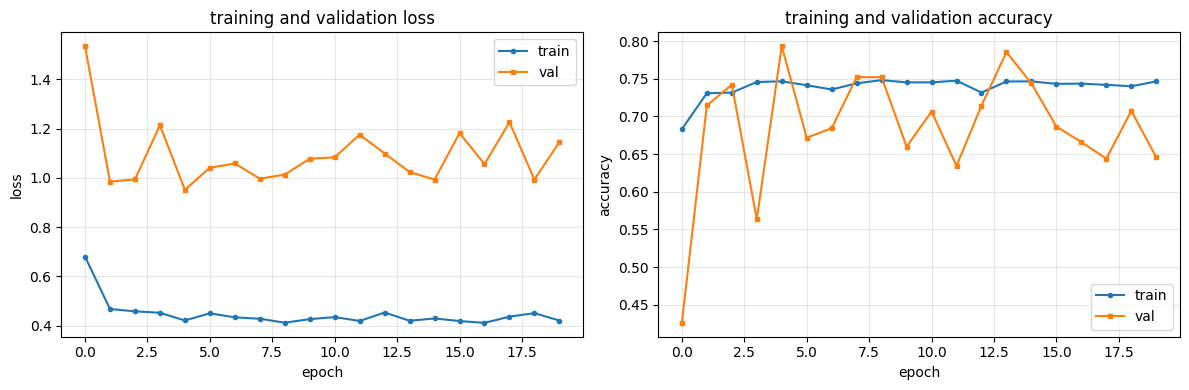

In [13]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.plot(history['train_loss'], label='train', marker='o', markersize=3)
ax1.plot(history['val_loss'],   label='val',   marker='s', markersize=3)
ax1.set_xlabel('epoch')
ax1.set_ylabel('loss')
ax1.set_title('training and validation loss')
ax1.legend()
ax1.grid(True, alpha=0.3)

ax2.plot(history['train_acc'], label='train', marker='o', markersize=3)
ax2.plot(history['val_acc'],   label='val',   marker='s', markersize=3)
ax2.set_xlabel('epoch')
ax2.set_ylabel('accuracy')
ax2.set_title('training and validation accuracy')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()
plt.close('all')


## 12b. Save Inference Metadata

In [14]:
import json

# save class labels and preprocessing config for inference
inference_config = {
    'class_names': class_names,
    'image_size': image_size,
    'mean': mean,
    'std': std,
    'num_classes': num_classes
}
with open(inference_config_path, 'w') as f:
    json.dump(inference_config, f, indent=2)

print(f'inference config saved to {inference_config_path}')


inference config saved to mobilenet_inference_config.json


## 13. Test Evaluation

In [15]:
model.load_state_dict(torch.load(model_save_path, weights_only=True))
model.eval()

all_predictions = []
all_labels      = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device, non_blocking=True)

        with autocast():
            outputs = model(images)

        _, predicted = outputs.max(1)
        all_predictions.extend(predicted.cpu().numpy())
        all_labels.extend(labels.numpy())

        del images, outputs

all_predictions = np.array(all_predictions)
all_labels      = np.array(all_labels)

print(f'test evaluation completed — {len(all_predictions)} samples')


/tmp/ipykernel_23/4031745452.py:11: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


test evaluation completed — 1793 samples


## 14. Calculate Metrics

In [16]:
# Calculate metrics
test_accuracy = accuracy_score(all_labels, all_predictions)
test_precision = precision_score(all_labels, all_predictions, average='weighted', zero_division=0)
test_recall = recall_score(all_labels, all_predictions, average='weighted', zero_division=0)
test_f1 = f1_score(all_labels, all_predictions, average='weighted', zero_division=0)

print('Test Set Performance:')
print(f'Accuracy:  {test_accuracy:.4f}')
print(f'Precision: {test_precision:.4f}')
print(f'Recall:    {test_recall:.4f}')
print(f'F1-Score:  {test_f1:.4f}')

Test Set Performance:
Accuracy:  0.8226
Precision: 0.8594
Recall:    0.8226
F1-Score:  0.8368


## 15. Classification Report

In [17]:
print('Classification Report:')
print(classification_report(all_labels, all_predictions, target_names=class_names, zero_division=0))

Classification Report:
               precision    recall  f1-score   support

        other       0.94      0.86      0.90      1482
       crater       0.39      0.57      0.46        89
    dark dune       0.71      0.89      0.79        66
 slope streak       0.48      0.49      0.48        49
  bright dune       0.47      0.94      0.62        16
impact ejecta       0.05      0.43      0.10         7
 swiss cheese       0.81      1.00      0.89        42
       spider       0.15      0.10      0.12        42

     accuracy                           0.82      1793
    macro avg       0.50      0.66      0.55      1793
 weighted avg       0.86      0.82      0.84      1793



## 16. Confusion Matrix

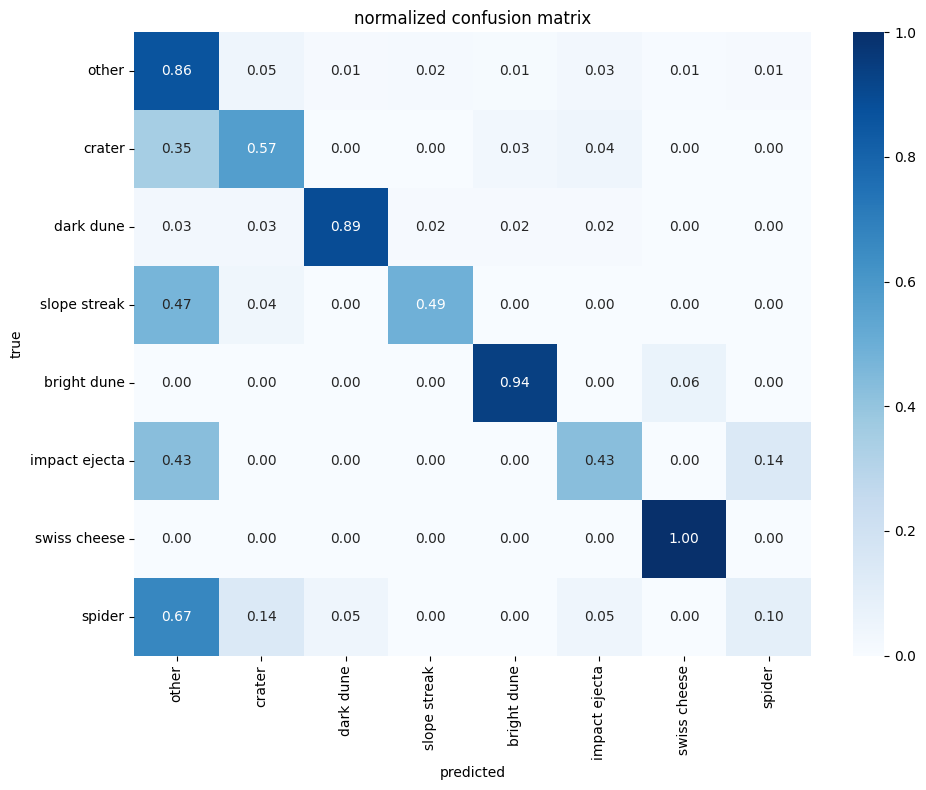

In [18]:
cm            = confusion_matrix(all_labels, all_predictions)
cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

plt.figure(figsize=(10, 8))
sns.heatmap(cm_normalized, annot=True, fmt='.2f', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel('predicted')
plt.ylabel('true')
plt.title('normalized confusion matrix')
plt.tight_layout()
plt.show()
plt.close('all')


## 17. Per-Class Performance

In [19]:
per_class_precision = precision_score(all_labels, all_predictions, average=None, zero_division=0)
per_class_recall = recall_score(all_labels, all_predictions, average=None, zero_division=0)
per_class_f1 = f1_score(all_labels, all_predictions, average=None, zero_division=0)

print('Per-Class Performance:')
for i, name in enumerate(class_names):
    print(f'{name}:')
    print(f'  Precision: {per_class_precision[i]:.4f}')
    print(f'  Recall:    {per_class_recall[i]:.4f}')
    print(f'  F1-Score:  {per_class_f1[i]:.4f}')

Per-Class Performance:
other:
  Precision: 0.9362
  Recall:    0.8617
  F1-Score:  0.8974
crater:
  Precision: 0.3893
  Recall:    0.5730
  F1-Score:  0.4636
dark dune:
  Precision: 0.7108
  Recall:    0.8939
  F1-Score:  0.7919
slope streak:
  Precision: 0.4800
  Recall:    0.4898
  F1-Score:  0.4848
bright dune:
  Precision: 0.4688
  Recall:    0.9375
  F1-Score:  0.6250
impact ejecta:
  Precision: 0.0545
  Recall:    0.4286
  F1-Score:  0.0968
swiss cheese:
  Precision: 0.8077
  Recall:    1.0000
  F1-Score:  0.8936
spider:
  Precision: 0.1538
  Recall:    0.0952
  F1-Score:  0.1176


## 18. Summary

In [20]:
print('Model Training Summary')
print(f'Architecture: MobileNetV2 with transfer learning')
print(f'Total parameters: {total_params:,}')
print(f'Trainable parameters: {trainable_params:,}')
print(f'\nTraining configuration:')
print(f'  Image size: {image_size}x{image_size}')
print(f'  Batch size: {batch_size}')
print(f'  Epochs: {num_epochs}')
print(f'  Learning rate: {learning_rate}')
print(f'\nDataset splits:')
print(f'  Training: {len(train_df)} samples')
print(f'  Validation: {len(val_df)} samples')
print(f'  Test: {len(test_df)} samples')
print(f'\nBest validation accuracy: {best_val_acc:.4f}')
print(f'\nTest set performance:')
print(f'  Accuracy:  {test_accuracy:.4f}')
print(f'  Precision: {test_precision:.4f}')
print(f'  Recall:    {test_recall:.4f}')
print(f'  F1-Score:  {test_f1:.4f}')


Model Training Summary
Architecture: MobileNetV2 with transfer learning
Total parameters: 2,234,120
Trainable parameters: 10,248

Training configuration:
  Image size: 224x224
  Batch size: 32
  Epochs: 50
  Learning rate: 0.001

Dataset splits:
  Training: 51058 samples
  Validation: 14959 samples
  Test: 1793 samples

Best validation accuracy: 0.7933

Test set performance:
  Accuracy:  0.8226
  Precision: 0.8594
  Recall:    0.8226
  F1-Score:  0.8368
